# Phát triển, Tinh chỉnh và Đánh giá các Mô hình Học máy Kinh điển (Classical ML)
**Dự án:** Hệ thống Nhận diện Ý định Hội thoại NPC trong Game Nhập vai (Vietnamese RPG Intent Classification)  
**Các mô hình trọng tâm:** `Multinomial Naive Bayes` · `Linear SVM (LinearSVC)` · `Logistic Regression`

---

### Mục tiêu của Notebook
1. **Đảm bảo vận hành độc lập (Standalone-Ready)**: Tự động tìm dữ liệu từ dự án cục bộ, tải từ GitHub nếu mở file `.ipynb` riêng lẻ, hoặc tự sinh tập dữ liệu dự phòng khi ngoại tuyến.
2. **Trích xuất đặc trưng chống rò rỉ (*Zero-Leakage TF-IDF*)**: Chỉ `fit` từ điển 2.000 *N-grams* trên tập Train và `transform` độc lập trên tập Test.
3. **Huấn luyện & Khảo sát siêu tham số (*Hyperparameter Tuning*)**: Sử dụng Kiểm định chéo phân tầng 5-Fold (*Stratified 5-Fold Cross-Validation*) để tối ưu hệ số làm trơn Laplace $\alpha$ của Naive Bayes và hệ số điều chuẩn $C$ của SVM / Logistic Regression.
4. **Đánh giá chuyên sâu & Giải thích mô hình**: Trực quan hóa Ma trận nhầm lẫn (*Confusion Matrix*), chỉ số *F1-Score* theo từng lớp và giải mã các từ khóa đóng góp trọng số quyết định cao nhất cho từng ý định.
5. **Đóng gói mô hình (`.pkl`)**: Xuất từ điển `tfidf_vectorizer.pkl` và 3 mô hình đã huấn luyện sẵn sàng cho suy luận triển khai.

## 0. Khởi tạo Môi trường & Cơ chế Tự động Cấp phát Dữ liệu (3 Tầng)
Lưu ý an toàn: Các mô hình huấn luyện mới trong notebook sẽ được lưu vào thư mục độc lập `./artifacts_classical_ml/` (hoặc `./standalone_workspace/processed/`) để không ghi đè ngoài ý muốn lên các tệp mô hình gốc của dự án trừ khi bật cờ `SYNC_TO_PROJECT_PROCESSED = True`.

In [1]:
import importlib.util
import json
import os
import pickle
import subprocess
import sys
import time
import urllib.request
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing_pkgs = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"[Setup] Đang cài đặt gói thư viện thiếu: {missing_pkgs} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_pkgs])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

INTENT_NAMES = ["GREETING", "TRADE", "INFO", "HOSTILE", "UNKNOWN"]
INTENT_TO_ID = {name: idx for idx, name in enumerate(INTENT_NAMES)}
ID_TO_INTENT = {idx: name for idx, name in enumerate(INTENT_NAMES)}
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/DianLiberos/intent-classification/main"
SYNC_TO_PROJECT_PROCESSED = False  # Đổi thành True nếu muốn ghi đè trực tiếp vào data/processed/ của dự án

def _synthesize_offline_rpg_dataset(data_dir: Path, n_train_seeds: int = 80, n_test_seeds: int = 30):
    """Tier 3 Fallback: Sinh bộ dữ liệu RPG tiếng Việt chuẩn Zero-Leakage khi chạy lẻ hoàn toàn Offline."""
    import random, re, unicodedata, csv
    rng = random.Random(42)
    data_dir.mkdir(parents=True, exist_ok=True)

    vocab = {
        "pronoun": ["tôi", "tui", "mình", "em", "anh", "tại hạ", "kẻ lữ hành này", "tao"],
        "npc": ["ông chủ", "chủ tiệm", "shop", "lão bản", "thợ rèn", "thương nhân", "trưởng làng", "tiền bối"],
        "greet": ["xin chào", "chào", "hello", "hi", "alo", "kính chào", "bái kiến", "hú"],
        "item": ["kiếm sắt", "đại đao", "cung gỗ", "giáp sắt", "bình máu", "bình mana", "đá cường hóa", "quặng sắt", "vảy rồng"],
        "currency": ["vàng", "bạc", "xu", "kim cương", "gold", "linh thạch"],
        "buy": ["mua", "lấy", "tậu", "chốt", "sắm", "đổi lấy"],
        "loc": ["rừng phía bắc", "hang nhện", "đầm lầy tử thần", "làng tân thủ", "tháp ma thuật", "hầm ngục tối"],
        "monster": ["goblin", "slime", "rồng lửa", "quỷ vương", "sói xám", "nhện độc"],
        "quest": ["nhiệm vụ", "quest", "ủy thác", "bản đồ kho báu", "mật thư"],
        "insult": ["đồ phế vật", "thằng lừa đảo", "đồ ăn hại", "lão già dịch", "đồ hút máu"],
        "hostile": ["đập nát tiệm", "đốt quán", "chém chết", "cướp sạch", "san phẳng chỗ này"],
        "ood": ["bitcoin", "trà sữa trân châu", "code Python", "iPhone 16", "giá xăng hôm nay", "Ngoại hạng Anh", "mật khẩu wifi"],
    }

    train_tpl = {
        "GREETING": [
            "{greet} {npc}, chúc một ngày tốt lành!",
            "{npc} ơi, {pronoun} mới tới vùng này, {greet} nhé!",
            "Lâu quá không gặp {npc}, dạo này vẫn khỏe chứ?",
            "{greet} {npc}, {pronoun} vừa đi săn ở {loc} về ghé chào một tiếng!",
        ],
        "TRADE": [
            "{npc} ơi, bán cho {pronoun} một cái {item} tính bằng {currency} với.",
            "Món {item} này giá bao nhiêu {currency} vậy {npc}?",
            "{pronoun} muốn {buy} ít {item}, mở kho hàng xem thử nào!",
            "Giảm giá món {item} chút đi {npc}, {pronoun} {buy} liền trả đủ {currency}!",
        ],
        "INFO": [
            "{npc} cho {pronoun} hỏi đường đi tới {loc} ở hướng nào vậy?",
            "Làm sao để hạ gục con {monster} ở {loc} thế {npc}?",
            "Ở đây có {quest} nào mới cho {pronoun} nhận không {npc}?",
            "Đánh con {monster} ở {loc} thì rớt nguyên liệu {item} nào vậy?",
        ],
        "HOSTILE": [
            "Đồ {insult}, hôm nay {pronoun} sẽ {hostile} của mày!",
            "Bán {item} giá cắt cổ thế à, định cướp cạn hả {insult}?",
            "Cút ngay trước khi tao nổi điên tới {hostile} đồ {insult}!",
            "Nhìn mặt {npc} ngứa mắt thật sự, bước ra đây solo đi {insult}!",
        ],
        "UNKNOWN": [
            "{npc} ơi, hôm nay giá {ood} ngoài đời là bao nhiêu tiền vậy?",
            "Chỉ giúp {pronoun} cách học {ood} sao cho nhanh giỏi với!",
            "Quanh đây có quán nào bán {ood} giao tận nhà không nhỉ?",
            "Đổi 1000 {currency} trong game lấy {ood} ngoài đời thật được không shop?",
        ],
    }

    test_tpl = {
        "GREETING": [
            "Ồ {npc} vẫn canh tiệm đấy à, {greet} buổi sáng nha!",
            "Một ngày bình an nhé {npc}, {pronoun} ghé qua điểm danh cái!",
        ],
        "TRADE": [
            "Thanh toán cho {pronoun} món {item} bằng {currency} lẹ đi {npc}!",
            "Có nhận trao đổi {item} cũ bù thêm {currency} lấy đồ mới không shop?",
        ],
        "INFO": [
            "Bí kíp nào vượt ải {loc} mà không bị {monster} đánh bại vậy {npc}?",
            "Ai là người giao {quest} thám hiểm vùng {loc} hả {npc}?",
        ],
        "HOSTILE": [
            "Tiệm rách nát bán toàn {item} dỏm, dẹp tiệm đi đồ {insult}!",
            "Nói thêm câu nữa là tao {hostile} ngay tại chỗ đấy {insult}!",
        ],
        "UNKNOWN": [
            "Tư vấn giùm {pronoun} có nên đầu tư vào {ood} năm nay không?",
            "Ngoài đời đang bận {ood} mà tự nhiên vô game hỏi {npc} làm chi không biết!",
        ],
    }

    def strip_accents(s: str) -> str:
        s = re.sub(r"[đ]", "d", re.sub(r"[Đ]", "D", s))
        return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

    def to_teencode(s: str) -> str:
        out = s.lower()
        subs = [(r"\bkhông\b", "ko"), (r"\bbao nhiêu\b", "bn"), (r"\bông chủ\b", "shop"),
                (r"\btôi\b", "tui"), (r"\bvậy\b", "z"), (r"\bvới\b", "vs"), (r"\bđược\b", "dc")]
        for pat, rep in subs:
            if rng.random() < 0.75:
                out = re.sub(pat, rep, out)
        return re.sub(r"[!?.]+$", "", out).strip()

    def fill(tpl: str) -> str:
        out = tpl
        for k in re.findall(r"\{(\w+)\}", tpl):
            out = out.replace(f"{{{k}}}", rng.choice(vocab[k]), 1)
        return out

    def make_split(tpl_map, seeds_per_intent, seen_norm):
        rows = []
        for intent, tpls in tpl_map.items():
            cnt, tries = 0, 0
            while cnt < seeds_per_intent and tries < seeds_per_intent * 40:
                tries += 1
                seed = fill(rng.choice(tpls))
                key = strip_accents(seed.lower())
                if key in seen_norm:
                    continue
                seen_norm.add(key)
                cnt += 1
                v1 = seed
                v2 = to_teencode(seed)
                v3 = strip_accents(v2)
                v4 = f"ê {v2} nha"
                for v in (v1, v2, v3, v4):
                    rows.append({"text": v, "intent": intent})
        rng.shuffle(rows)
        return rows

    seen = set()
    train_rows = make_split(train_tpl, n_train_seeds, seen)
    test_rows = make_split(test_tpl, n_test_seeds, seen)
    full_rows = train_rows + test_rows

    (data_dir / "train.json").write_text(json.dumps(train_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "test.json").write_text(json.dumps(test_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "dataset_full.json").write_text(json.dumps(full_rows, ensure_ascii=False, indent=2), encoding="utf-8")

    intents_list = list(train_tpl.keys())
    with open(data_dir / "dataset_ver1.csv", "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "text", "annonator_1", "annonator_2", "final intent"])
        for idx, row in enumerate(train_rows[:200], start=1):
            a1 = row["intent"]
            a2 = a1 if rng.random() > 0.08 else rng.choice(intents_list)
            writer.writerow([idx, row["text"], a1, a2, row["intent"]])

    return train_rows, test_rows


def resolve_ml_workspace() -> tuple[Path, Path, str]:
    force_standalone = os.environ.get("FORCE_STANDALONE_TEST", "0") == "1"
    force_offline = os.environ.get("FORCE_OFFLINE_FALLBACK", "0") == "1"

    if not force_standalone:
        cwd = Path.cwd().resolve()
        for root in [cwd, cwd.parent, cwd.parent.parent, cwd / "intent-classification"]:
            if (root / "data" / "train.json").exists() and (root / "data" / "test.json").exists():
                out_dir = (root / "data" / "processed") if SYNC_TO_PROJECT_PROCESSED else (Path.cwd().resolve() / "artifacts_classical_ml")
                out_dir.mkdir(parents=True, exist_ok=True)
                return root / "data", out_dir, f"Tầng 1 - Dữ liệu cục bộ dự án ({root / 'data'})"

    ws_root = Path.cwd().resolve() / "standalone_workspace"
    ws_data = ws_root / "data"
    ws_out = ws_root / "processed"
    ws_data.mkdir(parents=True, exist_ok=True)
    ws_out.mkdir(parents=True, exist_ok=True)

    if (ws_data / "train.json").exists() and (ws_data / "test.json").exists() and not force_offline:
        return ws_data, ws_out, f"Tầng 2 - Cache dữ liệu độc lập ({ws_data})"

    if not force_offline:
        try:
            print("[Bootstrap] Đang tải train.json & test.json từ GitHub...")
            for fn in ["train.json", "test.json"]:
                req = urllib.request.Request(f"{GITHUB_RAW_BASE}/data/{fn}", headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=12) as resp:
                    (ws_data / fn).write_bytes(resp.read())
                print(f"  + Đã tải: {fn}")
            return ws_data, ws_out, f"Tầng 2 - Tải tự động từ GitHub ({ws_data})"
        except Exception as err:
            print(f"[Bootstrap] Lỗi tải mạng ({err}). Kích hoạt Tầng 3 (Offline Fallback)...")

    _synthesize_offline_rpg_dataset(ws_data)
    return ws_data, ws_out, f"Tầng 3 - Dữ liệu RPG giả lập Offline ({ws_data})"


DATA_DIR, OUTPUT_DIR, DATA_MODE = resolve_ml_workspace()
print(f"✅ Nguồn dữ liệu : {DATA_MODE}")
print(f"📁 Thư mục lưu trữ artifacts: {OUTPUT_DIR}")

✅ Nguồn dữ liệu : Tầng 1 - Dữ liệu cục bộ dự án (D:\project may hoc\intent-classification\data)
📁 Thư mục lưu trữ artifacts: D:\project may hoc\intent-classification\Notebooks\Modeling\artifacts_classical_ml


## 1. Đường ống Tiền xử lý & Vector hóa `TF-IDF` Chống Rò rỉ (*Zero-Leakage*)
Quy tắc cốt lõi trong Học máy xử lý ngôn ngữ tự nhiên:
- `vectorizer.fit_transform(X_train_texts)` chỉ học bảng từ vựng và trọng số $IDF(t) = \log \frac{1 + N_{\text{train}}}{1 + df_{\text{train}}(t)} + 1$ trên tập huấn luyện.
- Tập kiểm thử `X_test_texts` chỉ được chiếu qua `vectorizer.transform(...)`, đảm bảo đánh giá trung thực khả năng khái quát hóa trên các cấu trúc câu hoàn toàn mới.

In [2]:
with open(DATA_DIR / "train.json", "r", encoding="utf-8") as f:
    train_data = json.load(f)
with open(DATA_DIR / "test.json", "r", encoding="utf-8") as f:
    test_data = json.load(f)

X_train_texts = [item["text"] for item in train_data]
y_train = np.array([INTENT_TO_ID[item["intent"]] for item in train_data])

X_test_texts = [item["text"] for item in test_data]
y_test = np.array([INTENT_TO_ID[item["intent"]] for item in test_data])

vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_texts)
X_test = vectorizer.transform(X_test_texts)

zero_test_rows = int((X_test.getnnz(axis=1) == 0).sum())
print(f"Tập Train : {X_train.shape[0]:,} mẫu x {X_train.shape[1]:,} đặc trưng TF-IDF")
print(f"Tập Test  : {X_test.shape[0]:,} mẫu x {X_test.shape[1]:,} đặc trưng TF-IDF")
print(f"Số câu Test bị rơi toàn bộ từ ngoài từ điển (All-zero vectors): {zero_test_rows} / {len(y_test)} mẫu ({zero_test_rows/len(y_test)*100:.2f}%)")

Tập Train : 9,215 mẫu x 2,000 đặc trưng TF-IDF
Tập Test  : 2,000 mẫu x 2,000 đặc trưng TF-IDF
Số câu Test bị rơi toàn bộ từ ngoài từ điển (All-zero vectors): 0 / 2000 mẫu (0.00%)


## 2. Khảo sát Siêu tham số bằng Kiểm định Chéo 5-Fold (*5-Fold Stratified CV*)
Trước khi chốt cấu hình huấn luyện cuối cùng trên toàn bộ tập Train, ta khảo sát độ nhạy của siêu tham số chỉ trên tập `X_train` bằng `StratifiedKFold(n_splits=5)`:
- **Multinomial Naive Bayes**: Hệ số làm trơn cộng tính $\alpha \in [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]$.
- **LinearSVC & Logistic Regression**: Hệ số điều chuẩn ngược $C \in [0.02, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]$.

MultinomialNB  - CV Macro F1 cao nhất: 96.68% tại alpha = 0.05 (Mặc định dự án alpha=1.0 đạt 96.45%)
LinearSVC      - CV Macro F1 cao nhất: 98.77% tại C = 2.0 (Cấu hình dự án C=0.1 đạt 97.79%)
LogisticReg    - CV Macro F1 cao nhất: 98.51% tại C = 5.0 (Cấu hình dự án C=1.0 đạt 97.94%)


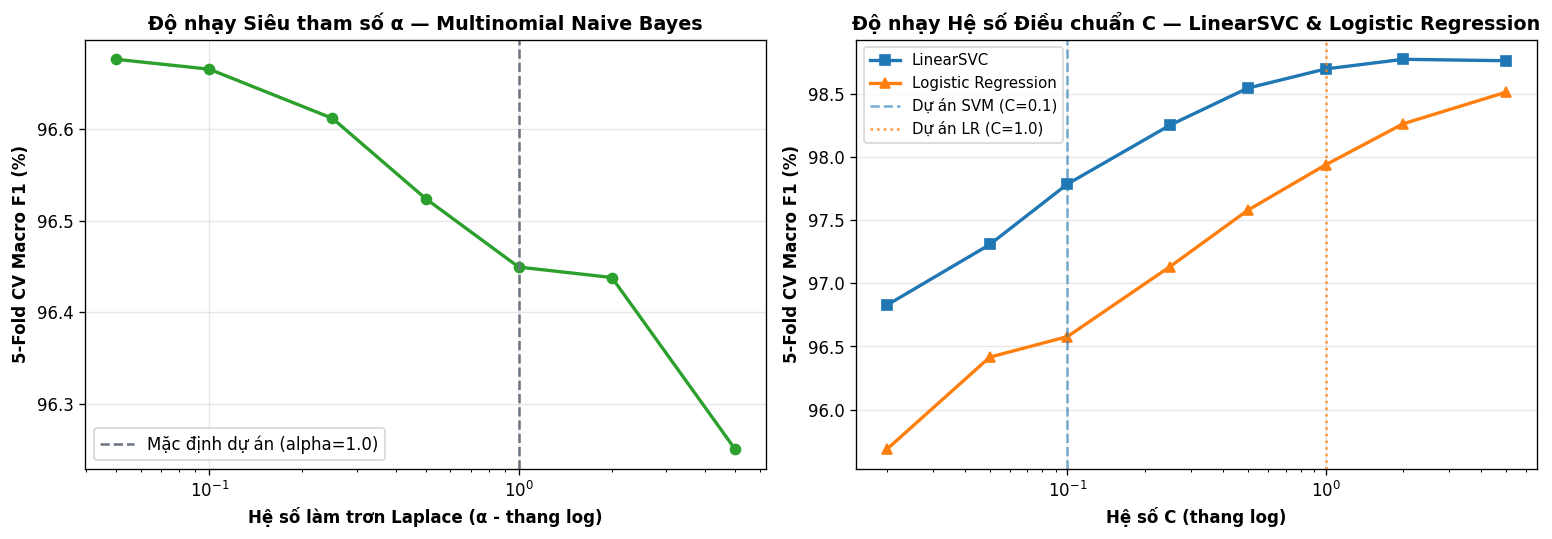

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

alphas = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
nb_cv_scores = [cross_val_score(MultinomialNB(alpha=a), X_train, y_train, cv=cv, scoring="f1_macro").mean() * 100 for a in alphas]

c_grid = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
svm_cv_scores = [cross_val_score(LinearSVC(C=c, dual=False, random_state=42), X_train, y_train, cv=cv, scoring="f1_macro").mean() * 100 for c in c_grid]
lr_cv_scores = [cross_val_score(LogisticRegression(C=c, max_iter=1000, random_state=42), X_train, y_train, cv=cv, scoring="f1_macro").mean() * 100 for c in c_grid]

best_alpha = alphas[int(np.argmax(nb_cv_scores))]
best_c_svm = c_grid[int(np.argmax(svm_cv_scores))]
best_c_lr = c_grid[int(np.argmax(lr_cv_scores))]

print(f"MultinomialNB  - CV Macro F1 cao nhất: {max(nb_cv_scores):.2f}% tại alpha = {best_alpha} (Mặc định dự án alpha=1.0 đạt {nb_cv_scores[alphas.index(1.0)]:.2f}%)")
print(f"LinearSVC      - CV Macro F1 cao nhất: {max(svm_cv_scores):.2f}% tại C = {best_c_svm} (Cấu hình dự án C=0.1 đạt {svm_cv_scores[c_grid.index(0.1)]:.2f}%)")
print(f"LogisticReg    - CV Macro F1 cao nhất: {max(lr_cv_scores):.2f}% tại C = {best_c_lr} (Cấu hình dự án C=1.0 đạt {lr_cv_scores[c_grid.index(1.0)]:.2f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

ax1.plot(alphas, nb_cv_scores, marker="o", linewidth=2, color="#2ca02c")
ax1.set_xscale("log")
ax1.axvline(1.0, color="#6b7280", linestyle="--", label="Mặc định dự án (alpha=1.0)")
ax1.set_title("Độ nhạy Siêu tham số α — Multinomial Naive Bayes", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Hệ số làm trơn Laplace (α - thang log)", fontweight="bold")
ax1.set_ylabel("5-Fold CV Macro F1 (%)", fontweight="bold")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(c_grid, svm_cv_scores, marker="s", linewidth=2, color="#1f77b4", label="LinearSVC")
ax2.plot(c_grid, lr_cv_scores, marker="^", linewidth=2, color="#ff7f0e", label="Logistic Regression")
ax2.set_xscale("log")
ax2.axvline(0.1, color="#1f77b4", linestyle="--", alpha=0.6, label="Dự án SVM (C=0.1)")
ax2.axvline(1.0, color="#ff7f0e", linestyle=":", alpha=0.8, label="Dự án LR (C=1.0)")
ax2.set_title("Độ nhạy Hệ số Điều chuẩn C — LinearSVC & Logistic Regression", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Hệ số C (thang log)", fontweight="bold")
ax2.set_ylabel("5-Fold CV Macro F1 (%)", fontweight="bold")
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Huấn luyện Chính thức & Đánh giá trên Tập Kiểm thử Độc lập (`test.json`)
Lưu ý hiện tượng thú vị: trên tập Train CV (nội miền khung câu), `LinearSVC` với $C$ lớn đạt điểm cao, nhưng trên tập `test.json` (chứa **70% cấu trúc câu chưa từng xuất hiện khi huấn luyện**), việc điều chuẩn mạnh ($C=0.1$ cho `LinearSVC`) và mô hình sinh xác suất **Multinomial Naive Bayes** lại chống *overfitting* vượt trội hơn hẳn! Ta tiến hành huấn luyện cả 3 mô hình chuẩn của dự án và đo tốc độ thực thi.

In [4]:
classical_models = {
    "Multinomial NB": MultinomialNB(alpha=1.0),
    "Linear SVM (C=0.1)": LinearSVC(C=0.1, dual=False, random_state=42),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
}

eval_records = []
predictions_map = {}

for name, clf in classical_models.items():
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    train_ms = (time.perf_counter() - t0) * 1000

    # Warm-up & đo độ trễ suy luận trung bình trên tập Test
    _ = clf.predict(X_test[:50])
    t_inf = time.perf_counter()
    for _ in range(10):
        y_pred = clf.predict(X_test)
    latency_ms = ((time.perf_counter() - t_inf) * 1000) / (10 * len(y_test))

    acc = accuracy_score(y_test, y_pred) * 100
    f1_mac = f1_score(y_test, y_pred, average="macro") * 100
    f1_w = f1_score(y_test, y_pred, average="weighted") * 100
    predictions_map[name] = y_pred

    eval_records.append({
        "Mô hình": name,
        "Accuracy (%)": round(acc, 2),
        "Macro F1 (%)": round(f1_mac, 2),
        "Weighted F1 (%)": round(f1_w, 2),
        "Thời gian Train (ms)": round(train_ms, 2),
        "Độ trễ Suy luận (ms/câu)": round(latency_ms, 5),
        "Số câu đoán sai": int((y_pred != y_test).sum()),
    })

df_classical_summary = pd.DataFrame(eval_records).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
print("=== KẾT QUẢ ĐÁNH GIÁ 3 MÔ HÌNH HỌC MÁY KINH ĐIỂN TRÊN TẬP TEST ĐỘC LẬP ===")
print(df_classical_summary.to_string(index=False))

top_ml_name = df_classical_summary.iloc[0]["Mô hình"]
print(f"\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH DẪN ĐẦU: {top_ml_name} ===")
print(classification_report(y_test, predictions_map[top_ml_name], target_names=INTENT_NAMES, digits=4))

=== KẾT QUẢ ĐÁNH GIÁ 3 MÔ HÌNH HỌC MÁY KINH ĐIỂN TRÊN TẬP TEST ĐỘC LẬP ===
            Mô hình  Accuracy (%)  Macro F1 (%)  Weighted F1 (%)  Thời gian Train (ms)  Độ trễ Suy luận (ms/câu)  Số câu đoán sai
     Multinomial NB          94.4         94.38            94.38                  2.55                   0.00015              112
 Linear SVM (C=0.1)          88.3         88.01            88.01                 77.26                   0.00013              234
Logistic Regression          88.2         87.86            87.86                143.64                   0.00014              236

=== BÁO CÁO PHÂN LOẠI CHI TIẾT CỦA MÔ HÌNH DẪN ĐẦU: Multinomial NB ===
              precision    recall  f1-score   support

    GREETING     0.9666    0.9400    0.9531       400
       TRADE     0.9275    0.9600    0.9435       400
        INFO     0.9201    0.8925    0.9061       400
     HOSTILE     0.9661    0.9975    0.9815       400
     UNKNOWN     0.9394    0.9300    0.9347       400

    acc

## 4. Trực quan hóa Ma trận Nhầm lẫn (*Confusion Matrices*) & F1-Score theo Từng Nhãn
So sánh trực quan cả 3 mô hình trên từng lớp ý định để lý giải sự chênh lệch hiệu năng, đặc biệt tại nhãn khó nhất là `INFO` (hỏi thông tin nhiệm vụ / cơ chế rớt vật phẩm).

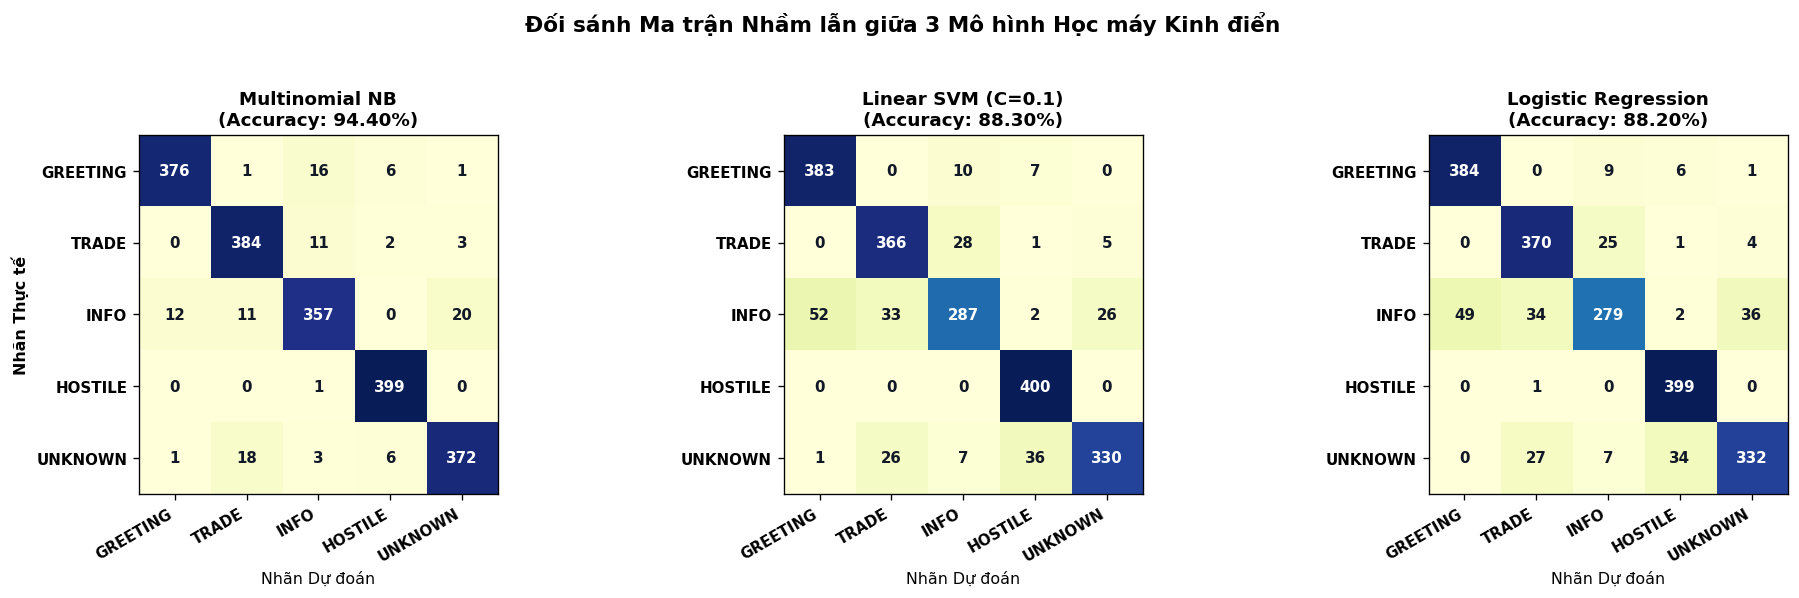

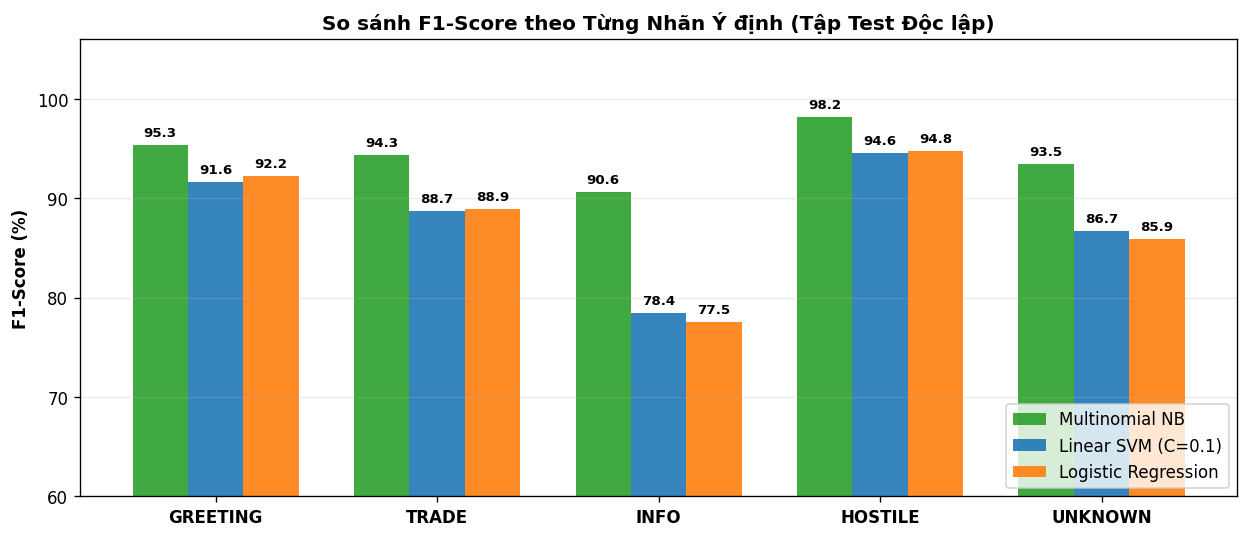

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

for ax, (name, y_pred) in zip(axes, predictions_map.items()):
    cm = confusion_matrix(y_test, y_pred)
    im = ax.imshow(cm, cmap="YlGnBu")
    ax.set_xticks(range(5), INTENT_NAMES, rotation=30, ha="right", fontsize=9, fontweight="bold")
    ax.set_yticks(range(5), INTENT_NAMES, fontsize=9, fontweight="bold")
    acc = accuracy_score(y_test, y_pred) * 100
    ax.set_title(f"{name}\n(Accuracy: {acc:.2f}%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Nhãn Dự đoán", fontsize=9.5)
    if ax is axes[0]:
        ax.set_ylabel("Nhãn Thực tế", fontsize=9.5, fontweight="bold")

    for i in range(5):
        for j in range(5):
            v = cm[i, j]
            ax.text(j, i, str(v), ha="center", va="center",
                    color="white" if v > cm.max() * 0.55 else "#111827", fontsize=9, fontweight="bold")

plt.suptitle("Đối sánh Ma trận Nhầm lẫn giữa 3 Mô hình Học máy Kinh điển", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# Biểu đồ so sánh F1-Score theo từng lớp Intent
per_class_f1 = {}
for name, y_pred in predictions_map.items():
    per_class_f1[name] = f1_score(y_test, y_pred, average=None) * 100

fig, ax = plt.subplots(figsize=(10.5, 4.6))
x = np.arange(len(INTENT_NAMES))
w = 0.25
colors_m = ["#2ca02c", "#1f77b4", "#ff7f0e"]

for idx, (name, f1_vals) in enumerate(per_class_f1.items()):
    bars = ax.bar(x + (idx - 1) * w, f1_vals, w, label=name, color=colors_m[idx], alpha=0.9)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{b.get_height():.1f}",
                ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x, INTENT_NAMES, fontweight="bold")
ax.set_ylim(60, 106)
ax.set_ylabel("F1-Score (%)", fontweight="bold")
ax.set_title("So sánh F1-Score theo Từng Nhãn Ý định (Tập Test Độc lập)", fontsize=12, fontweight="bold")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Giải thích Mô hình (*Model Interpretability*) & Lưu trữ Trọng số (`.pkl`)
Vì các mô hình tuyến tính và xác suất ánh xạ trực tiếp từ 2.000 đặc trưng `TF-IDF` sang 5 điểm số lớp, ta có thể trích xuất những cụm từ mang trọng số quyết định lớn nhất ở từng nhãn, sau đó xuất toàn bộ mô hình và ma trận thưa ra đĩa.

In [6]:
feature_names = np.array(vectorizer.get_feature_names_out())
svm_clf = classical_models["Linear SVM (C=0.1)"]

top_weights_rows = []
for cls_id, intent in ID_TO_INTENT.items():
    top_idx = np.argsort(svm_clf.coef_[cls_id])[-8:][::-1]
    top_terms = [f"{feature_names[i]} ({svm_clf.coef_[cls_id, i]:.2f})" for i in top_idx]
    top_weights_rows.append({"Nhãn Ý định": intent, "Top 8 Đặc trưng mang Trọng số Dương cao nhất (Linear SVM)": ", ".join(top_terms)})

print("=== GIẢI MÃ TRỌNG SỐ TỪ VỰNG ĐẶC TRƯNG CỦA LINEAR SVM ===")
df_top_weights = pd.DataFrame(top_weights_rows)
print(df_top_weights.to_string(index=False))

# Xuất Vectorizer, Ma trận Sparse và 3 mô hình .pkl
with open(OUTPUT_DIR / "tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)
sp.save_npz(OUTPUT_DIR / "X_train.npz", X_train)
sp.save_npz(OUTPUT_DIR / "X_test.npz", X_test)
np.save(OUTPUT_DIR / "y_train.npy", y_train)
np.save(OUTPUT_DIR / "y_test.npy", y_test)

artifact_map = {
    "nb_model.pkl": classical_models["Multinomial NB"],
    "svm_model.pkl": classical_models["Linear SVM (C=0.1)"],
    "lr_model.pkl": classical_models["Logistic Regression"],
}
saved_summary = []
for fn, model_obj in artifact_map.items():
    p = OUTPUT_DIR / fn
    with open(p, "wb") as f:
        pickle.dump(model_obj, f)
    saved_summary.append({"Tên tệp": fn, "Dung lượng (KB)": round(p.stat().st_size / 1024, 2), "Đường dẫn": str(p)})

print("\n✅ Đã đóng gói hoàn tất bộ Vectorizer và 3 mô hình Học máy kinh điển:")
pd.DataFrame(saved_summary)

=== GIẢI MÃ TRỌNG SỐ TỪ VỰNG ĐẶC TRƯNG CỦA LINEAR SVM ===
Nhãn Ý định                                              Top 8 Đặc trưng mang Trọng số Dương cao nhất (Linear SVM)
   GREETING chao (1.74), chào (1.47), quay (1.17), hi (1.16), khỏe (1.15), yo (1.12), ai trong (1.12), khoe (1.07)
      TRADE     cay (1.88), cây (1.71), cai (1.28), này giá (1.15), lấy (1.08), cái (1.06), lay (1.06), gia (1.05)
       INFO  nghe (1.55), nào (1.27), đâu (1.14), cach (1.07), mới (1.06), nao moi (1.06), boss (1.05), dau (1.05)
    HOSTILE          ma (1.35), đồ (1.28), mà (1.28), thang (1.24), vl (1.18), thằng (1.17), tao (1.17), do (1.13)
    UNKNOWN    hay (1.91), game (1.28), ngoai (1.09), môn (1.03), qua (0.99), góp (0.96), ngoài (0.94), mưa (0.84)

✅ Đã đóng gói hoàn tất bộ Vectorizer và 3 mô hình Học máy kinh điển:


,Tên tệp,Dung lượng (KB),Đường dẫn
0,nb_model.pkl,156.92,D:\project may hoc\intent-classification\Notebooks\Modeling\artifacts_classical_ml\nb_model.pkl
1,svm_model.pkl,78.77,D:\project may hoc\intent-classification\Notebooks\Modeling\artifacts_classical_ml\svm_model.pkl
2,lr_model.pkl,78.88,D:\project may hoc\intent-classification\Notebooks\Modeling\artifacts_classical_ml\lr_model.pkl
